# Modelo de Regressão Linear Simples

1 – Análise descritiva

2 – Análise de correlação

3 – Modelo de regressão

4 – Analise de resíduos

5 – Análise do Modelo

In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import lilliefors
import scipy.stats as stats

# Análise Descritiva
análise descritiva das medidas de tendência central

In [ ]:
dados = pd.read_csv('../dados/propaganda.csv')
dados.describe() #algumas informações sobre o dataframe

,TV,Radio,Jornal,Vendas
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
dados.shape()

(200, 4)

In [ ]:
dados.head()

,TV,Radio,Jornal,Vendas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
dados.dtypes #verifica os tipos dos dados que estamos trabalhando (importante) 

TV        float64
Radio     float64
Jornal    float64
Vendas    float64
dtype: object

In [15]:
dados.isnull().sum() #verificamos a presença de valores nulos

TV        0
Radio     0
Jornal    0
Vendas    0
dtype: int64

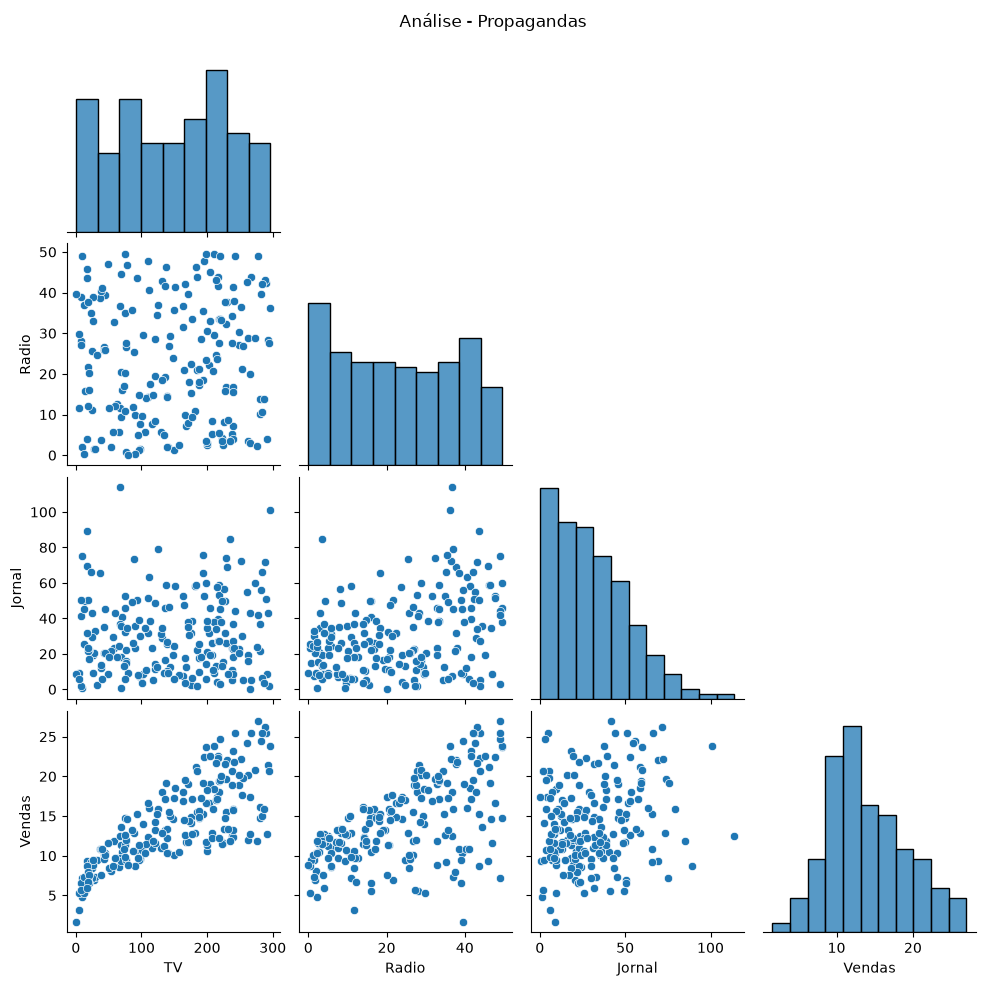

In [16]:
#Análise gráfica - pairplot
sns.pairplot(dados, corner=True) #(corner corta a metade do gráfico, ele é simétrico)
plt.suptitle("Análise - Propagandas")
plt.show()

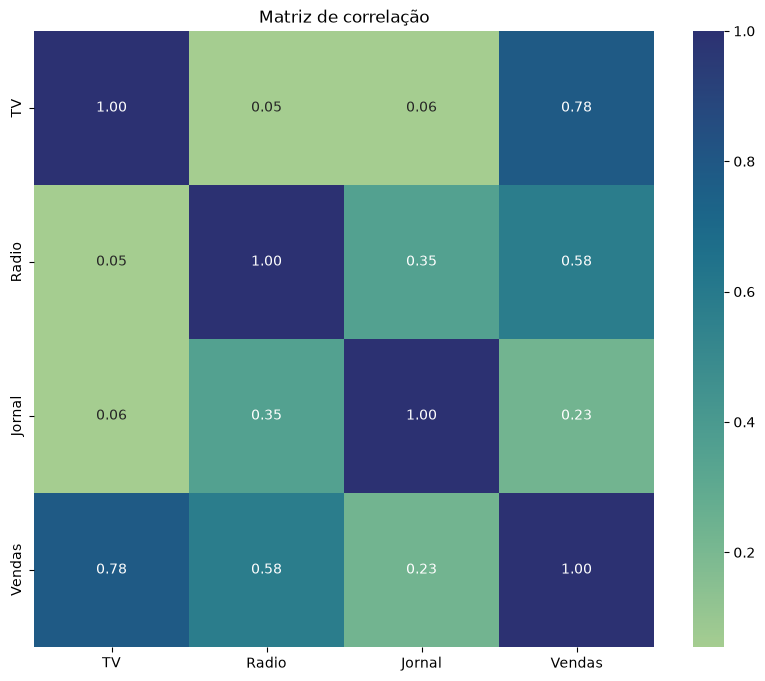

In [17]:
#Calculo da correlação
correlation_matrix = dados.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="crest", fmt=".2f")
plt.title("Matriz de correlação")
plt.show()

In [ ]:
# Regressão linear
# Var dependente - vendas
# Var independente - TV

X = dados['TV']
X_radio =  dados['Radio']
X_jornal = dados['Jornal']
y = dados['Vendas']

# Adicionando uma constante 
# Adiciona uma coluna de 1s (const) ao X. O statsmodels não estima o
# intercepto (β0) sozinho: sem essa coluna, a reta seria forçada a passar pela origem.
X = sm.add_constant(X)
X_radio = sm.add_constant(X_radio)
X_jornal = sm.add_constant(X_jornal)

# Ajustando o modelo
modelo_tv = sm.OLS(y, X).fit()
modelo_radio = sm.OLS(y, X_radio).fit()
modelo_jornal = sm.OLS(y, X_jornal).fit()

# Sumario do modelo
modelo_tv_sumary = modelo_tv.summary()
modelo_radio_sumary = modelo_radio.summary()
modelo_jornal_sumary = modelo_jornal.summary()

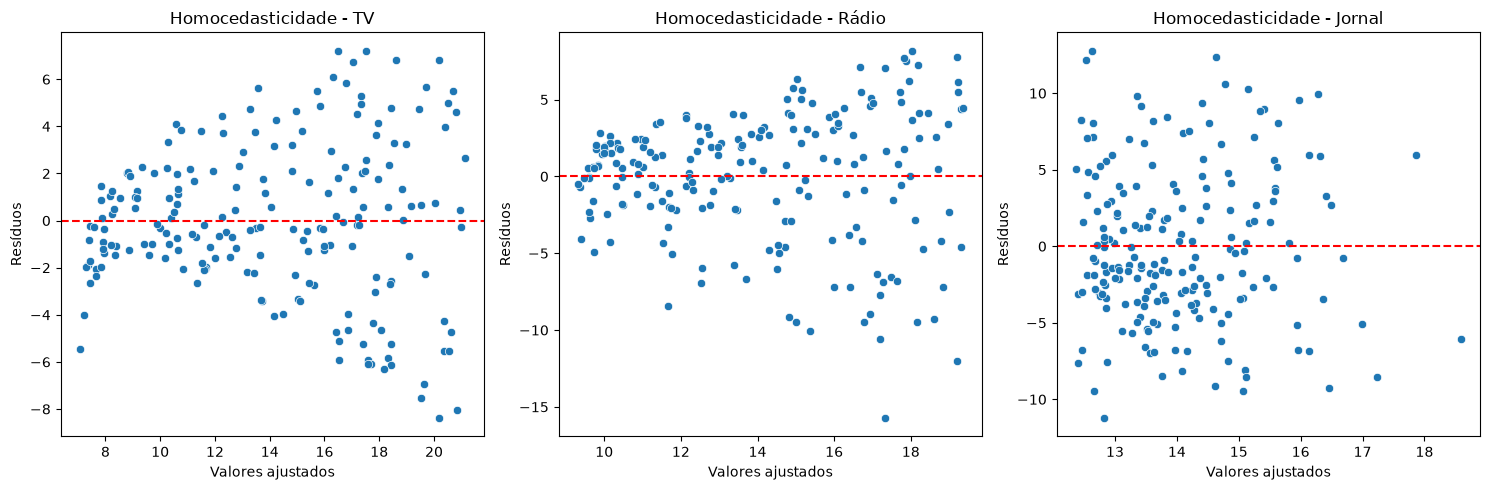

In [26]:
# Analisando os resíduos
residuos_tv = modelo_tv.resid
residuos_radio = modelo_radio.resid
residuos_jornal = modelo_jornal.resid

# Gráfico de homocedasticidade (uma única figura com 3 gráficos lado a lado)
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x=modelo_tv.fittedvalues, y=residuos_tv)
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Homocedasticidade - TV")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")

plt.subplot(1, 3, 2)
sns.scatterplot(x=modelo_radio.fittedvalues, y=residuos_radio)
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Homocedasticidade - Rádio")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")

plt.subplot(1, 3, 3)
sns.scatterplot(x=modelo_jornal.fittedvalues, y=residuos_jornal)
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Homocedasticidade - Jornal")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")

plt.tight_layout()
plt.show()

In [32]:
# Lista de tuplas: (nome para exibir, modelo já ajustado com .fit())
modelos = [
    ("modelo_tv", modelo_tv),
    ("modelo_radio", modelo_radio),
    ("modelo_jornal", modelo_jornal)
]

# Teste de homocedasticidade (Breusch-Pagan) para cada modelo
# H0: os resíduos têm variância constante (homocedasticidade)
# H1: a variância dos resíduos muda (heterocedasticidade)
for nome, modelo in modelos:

    # het_breuschpagan recebe:
    #   1) os resíduos do modelo (modelo.resid)
    #   2) as variáveis explicativas usadas no modelo, com a constante (modelo.model.exog)
    # e devolve 4 valores, sempre nesta ordem:
    #   estatistica -> estatística LM (multiplicador de Lagrange)
    #   p           -> p-valor da estatística LM
    #   f           -> estatística F
    #   fp          -> p-valor da estatística F
    estatistica, p, f, fp = het_breuschpagan(modelo.resid, modelo.model.exog)

    print(f'Estatística de teste para {nome}: {estatistica}')
    print(f'p-valor: {p}')
    print(f'f-valor: {f}')
    print(f'f_p-valor: {fp}')
    print()  # linha em branco para separar os modelos

Estatística de teste para modelo_tv: 48.037965662293594
p-valor: 4.180455907755742e-12
f-valor: 62.591404771514256
f_p-valor: 1.76184514256959e-13

Estatística de teste para modelo_radio: 36.645805174019586
p-valor: 1.4166353247317502e-09
f-valor: 44.418017132559605
f_p-valor: 2.5721402285198486e-10

Estatística de teste para modelo_jornal: 2.471728538393525
p-valor: 0.11591039135561061
f-valor: 2.477631414382325
f_p-valor: 0.11707253378080511



In [36]:
# Teste shapiro-wilk para normalidade
for nome, modelo in modelos:
    estatistica_shapiro, p_shapiro = stats.shapiro(modelo.resid)
    print(f"Estatistica de teste {nome} - {format(estatistica_shapiro)}")
    print('p-valor: {}'.format(p_shapiro))

Estatistica de teste modelo_tv - 0.9905306559346111
p-valor: 0.2133254992525529
Estatistica de teste modelo_radio - 0.9607170109681805
p-valor: 2.3665397310189958e-05
Estatistica de teste modelo_jornal - 0.9819678494620769
p-valor: 0.011395904246595298


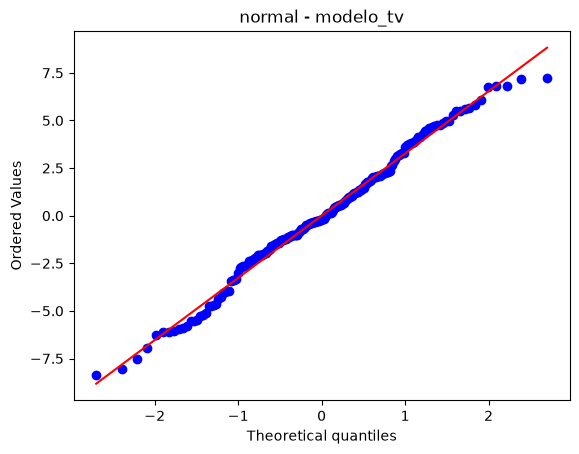

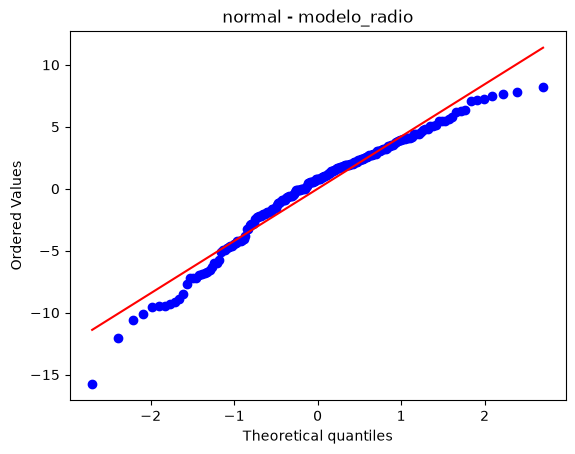

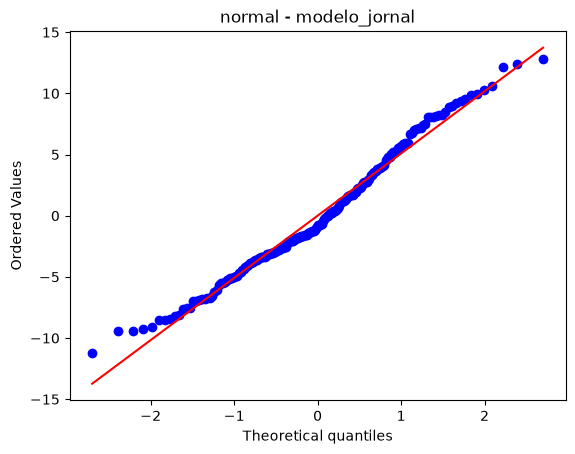

In [35]:
# Analise de normalidade QQ-Plot
for nome, modelo in modelos:
    stats.probplot(modelo.resid, dist='norm', plot=plt)
    plt.title(f"normal - {nome}")
    plt.show()

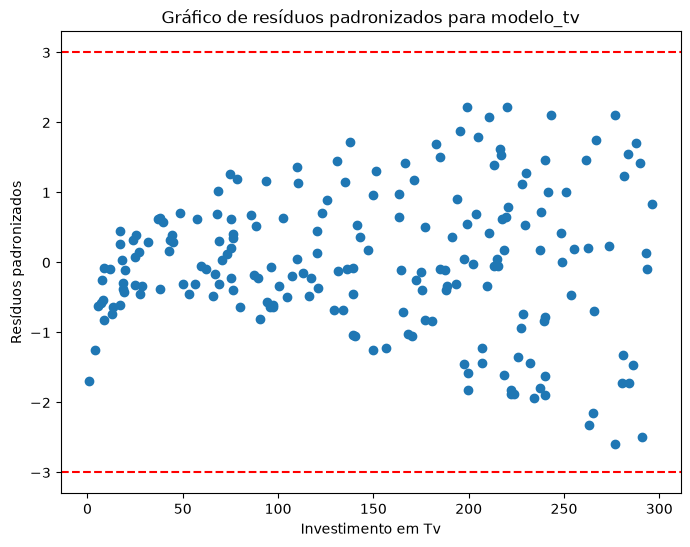

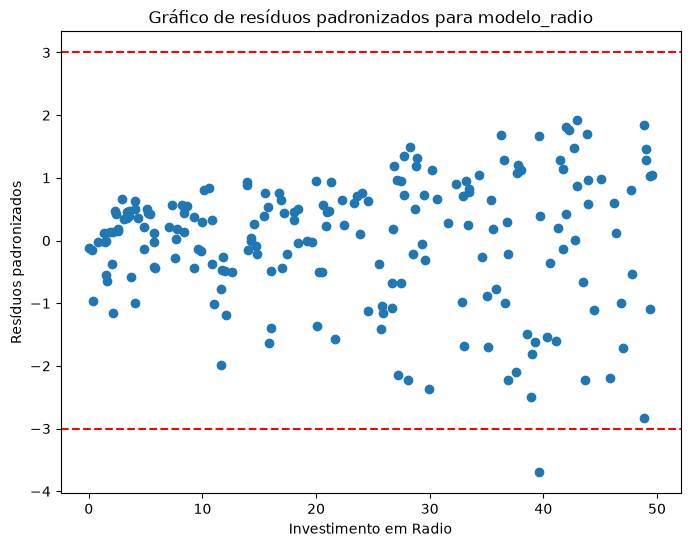

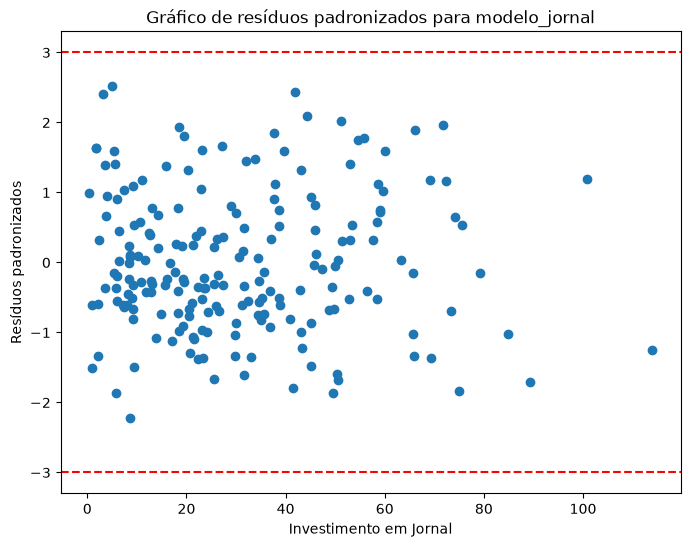

In [38]:
for nome, modelo in modelos:
    residuos_padronizados = modelo.get_influence().resid_studentized_internal

    plt.figure(figsize=(8, 6))
    plt.scatter(modelo.model.exog[:, 1], residuos_padronizados)  # coluna 1 = variável (a 0 é a const)
    plt.axhline(y=3, color='red', linestyle='--')
    plt.axhline(y=-3, color='red', linestyle='--')
    plt.title(f"Gráfico de resíduos padronizados para {nome}")
    plt.xlabel("Investimento em " + nome.split("_")[1].capitalize())
    plt.ylabel("Resíduos padronizados")
    plt.show()

In [40]:
for nome, modelo in modelos:
    print(str(modelo.summary()))

                            OLS Regression Results                            
Dep. Variable:                 Vendas   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.47e-42
Time:                        16:42:17   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.0326      0.458     15.360      0.0